In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Генерация тестовых данных (как на стр. 19)
np.random.seed(42)
X = np.random.randint(0, 2, size=(100, 12)) # 100 примеров, 12 бинарных признаков
Y = np.random.randint(0, 2, size=(100, 2)) # 100 примеров, 2 класса (one-hot encoding)

# Сохранение данных в файлы
np.savetxt('dataIn.txt', X, fmt='%d')
np.savetxt('dataOut.txt', Y, fmt='%d')

print("Файлы dataIn.txt и dataOut.txt созданы.")
print("Размер X:", X.shape)
print("Размер Y:", Y.shape)

Файлы dataIn.txt и dataOut.txt созданы.
Размер X: (100, 12)
Размер Y: (100, 2)


In [2]:
# Загружаем данные из файлов
X = np.loadtxt('dataIn.txt')
Y = np.loadtxt('dataOut.txt')

# Переводим Y из one-hot encoding в классы (0 или 1)
# Если в строке [1, 0] -> это класс 0, если [0, 1] -> класс 1
y = np.argmax(Y, axis=1)

# Разделяем на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Нормализация данных
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Размер Train:", X_train.shape)
print("Размер Test:", X_test.shape)
print("Распределение классов в Train:", np.bincount(y_train))
print("Распределение классов в Test:", np.bincount(y_test))

Размер Train: (70, 12)
Размер Test: (30, 12)
Распределение классов в Train: [48 22]
Распределение классов в Test: [17 13]


In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Создаем модель MLP (стр. 17)
model = keras.Sequential([
    # Входной слой (12 признаков) + 1 скрытый слой (16 нейронов) с активацией logsig (sigmoid)
    layers.Dense(16, activation='sigmoid', input_shape=(12,)), 
    # Выходной слой (1 нейрон для бинарной классификации)
    layers.Dense(1, activation='sigmoid') 
])

# Компиляция модели
model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

# Обучение модели
history = model.fit(X_train, y_train, 
                    epochs=50, 
                    batch_size=16, 
                    validation_data=(X_test, y_test),
                    verbose=1)

Epoch 1/50


D:\lab_1_ai\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.6857 - loss: 0.6484 - val_accuracy: 0.5667 - val_loss: 0.7084
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6857 - loss: 0.6449 - val_accuracy: 0.5667 - val_loss: 0.7115
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6857 - loss: 0.6418 - val_accuracy: 0.5667 - val_loss: 0.7132
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6857 - loss: 0.6393 - val_accuracy: 0.5667 - val_loss: 0.7147
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6857 - loss: 0.6368 - val_accuracy: 0.5667 - val_loss: 0.7167
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6857 - loss: 0.6349 - val_accuracy: 0.5667 - val_loss: 0.7190
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6857 - loss: 0.6328 - val_accuracy: 0.5667 - val_loss: 0.7216
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6857 - loss: 0.6306 - val_accuracy: 0.5667 - val_loss: 0.7241
Epoch 9/50


In [ ]:
!pip install tensorflow 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Accuracy: 0.5666666666666667

Classification Report:
              precision    recall  f1-score   support

           0       0.57      1.00      0.72        17
           1       0.00      0.00      0.00        13

    accuracy                           0.57        30
   macro avg       0.28      0.50      0.36        30
weighted avg       0.32      0.57      0.41        30



D:\lab_1_ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\lab_1_ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\lab_1_ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


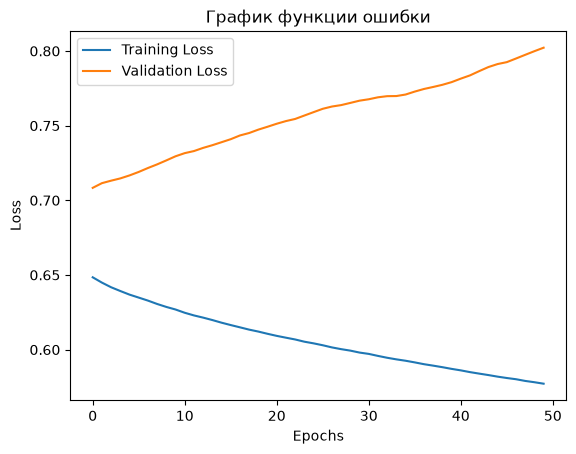

In [4]:
# Оцениваем качество на тестовой выборке
y_pred = (model.predict(X_test) > 0.5).astype("int32")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# График изменения функции ошибки (стр. 18)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('График функции ошибки')
plt.show()

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# 1. Логистическая регрессия
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))

# 2. Случайный лес
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Logistic Regression Accuracy: 0.3333333333333333
Random Forest Accuracy: 0.5
